# Revenue went up after the join: which checks catch fan-out before the aggregate

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-engineering-pro/fanout-join-audit/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-engineering-pro/fanout-join-audit/demo.ipynb)

A report of revenue by customer tier joins orders to a customer table, a product table and a promo-code table. If
any of those has more than one row per key, every matching order is counted twice, and the total goes up without an
error anywhere. This notebook builds a fictional shop, breaks the join six common ways, and runs six checks that a
team could put in front of the aggregate.

1. The engine
2. What each broken join does to the report
3. Which check fires
4. The declared test passes on the biggest defect
5. Why the row count understates the revenue error
6. Two defects that cancel
7. The chart
8. Try your own

## 1. The engine

Extracted from `explore.py` and `evidence.py` at build time. Seeded (`Generator(212)`), everything fictional, and
every number below matches `evidence.txt` exactly.

In [1]:
from __future__ import annotations

import json
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


class _E:  # evidence.py refers to the engine as E
    pass

SEED = 212


N_CUST, N_PROD, N_ORD = 2000, 200, 20000


TIERS = ["standard", "gold", "platinum"]


CATS = ["home", "garden", "kitchen", "tools", "outdoor"]


SCENARIOS = ["clean", "scd2_no_filter", "dup_load", "promo_bridge", "late_inner", "rows_offset", "revenue_offset",
             "orphan_dups"]


CHECKS = ["row_count", "revenue_total", "declared_unique", "join_key_unique", "referenced_key_unique", "pk_preserved"]


TOL = 0.001  # revenue_total passes within 0.1%


def make_world(seed: int = SEED) -> Dict[str, pd.DataFrame]:
    """Orders, a type-2 customer history, a product dimension and a promo bridge."""
    rng = np.random.default_rng(seed)
    tier = rng.choice(3, N_CUST, p=[0.75, 0.2, 0.05])
    cust = pd.DataFrame({"customer_id": np.arange(N_CUST), "tier": [TIERS[t] for t in tier]})
    # Bigger tiers order more often and spend more per order.
    w = np.array([1.0, 2.0, 4.0])[tier]
    oc = rng.choice(N_CUST, N_ORD, p=w / w.sum())
    amount = np.round(rng.lognormal(3.6, 0.6, N_ORD) * np.array([1.0, 2.5, 6.0])[tier[oc]], 2)
    orders = pd.DataFrame({"order_id": np.arange(N_ORD), "customer_id": oc,
                           "product_id": rng.integers(0, N_PROD, N_ORD), "amount": amount})
    # Type-2 history: customers who were upgraded keep their old row, flagged not current.
    # Upgrades happen to big spenders, so the duplicated customers are the valuable ones.
    up = np.flatnonzero((tier > 0) & (rng.random(N_CUST) < 0.18))
    old = cust.loc[up].assign(tier=[TIERS[t - 1] for t in tier[up]], valid_from="2024-01-01", is_current=False)
    cur = cust.assign(valid_from=np.where(np.isin(cust.customer_id, up), "2025-06-01", "2024-01-01"), is_current=True)
    scd2 = pd.concat([old, cur], ignore_index=True).sort_values(["customer_id", "valid_from"], ignore_index=True)
    prod = pd.DataFrame({"product_id": np.arange(N_PROD), "category": [CATS[i % 5] for i in range(N_PROD)]})
    # Promo bridge: most orders have no code, a few have one, fewer have two.
    r = rng.random(N_ORD)
    one = np.flatnonzero(r < 0.075)
    two = np.flatnonzero(r < 0.015)
    promo = pd.DataFrame({"order_id": np.concatenate([one, two]),
                          "promo_code": ["SPRING"] * len(one) + ["LOYAL"] * len(two)})
    return {"orders": orders, "scd2": scd2, "prod": prod, "promo": promo, "upgraded": pd.Series(up)}


def build(world: Dict[str, pd.DataFrame], scenario: str) -> Dict[str, object]:
    """One version of the report query. Returns the joined rows and the dimensions it actually used."""
    o, scd2, prod = world["orders"], world["scd2"], world["prod"]
    cust = scd2[scd2.is_current]  # the correct customer dimension: current rows only
    how = "left"
    if scenario in ("scd2_no_filter", "rows_offset", "revenue_offset"):
        cust = scd2  # forgot `WHERE is_current`
    if scenario == "dup_load":
        prod = pd.concat([prod, prod.iloc[[3, 41, 77, 102, 150, 188]]], ignore_index=True)  # six rows loaded twice
    if scenario == "orphan_dups":
        used = set(o.product_id)
        prod = pd.concat([prod, pd.DataFrame({"product_id": [900, 900, 901, 901], "category": "home"})],
                         ignore_index=True)  # duplicated discontinued products that no order references
        assert not used & {900, 901}
    if scenario in ("late_inner", "rows_offset", "revenue_offset"):
        how = "inner"
        o = late_arrivals(world, scenario)
    j = o.merge(cust[["customer_id", "tier"]], on="customer_id", how=how)
    j = j.merge(prod, on="product_id", how=how)
    dims = {"customer": (cust, ["customer_id"]), "product": (prod, ["product_id"])}
    if scenario == "promo_bridge":
        j = j.merge(world["promo"], on="order_id", how="left")  # "show the promo code on the report"
        dims["promo"] = (world["promo"], ["order_id"])
    return {"joined": j, "orders": o, "dims": dims}


def late_arrivals(world: Dict[str, pd.DataFrame], scenario: str) -> pd.DataFrame:
    """Orders whose customer has not landed in the dimension yet get an unknown id; an inner join drops them.

    rows_offset and revenue_offset are tuned on purpose: late orders are drawn from customers the missing filter
    does NOT duplicate, until the dropped rows (or the dropped revenue) equal what the duplication adds. How often
    real defects cancel is not measured here; the point is that the check CAN be fooled."""
    o = world["orders"].copy()
    rng = np.random.default_rng(SEED + 1)
    dup = o.customer_id.isin(world["upgraded"]).to_numpy()
    if scenario == "late_inner":
        late = rng.choice(len(o), int(0.03 * len(o)), replace=False)
    else:
        pool = rng.permutation(np.flatnonzero(~dup))
        if scenario == "rows_offset":
            late = pool[: int(dup.sum())]
        else:
            target = o.amount.to_numpy()[dup].sum()
            k = int(np.searchsorted(np.cumsum(o.amount.to_numpy()[pool]), target))
            late = pool[:k]
    n = len(late)
    o.loc[late, "customer_id"] = -1 - np.arange(n)
    return o


def checks(world: Dict[str, pd.DataFrame], b: Dict[str, object]) -> Dict[str, bool]:
    """True = the check FIRES (raises an alarm). Every check runs before anything is aggregated."""
    j, src = b["joined"], world["orders"]
    o_used = b["orders"]
    out: Dict[str, bool] = {}
    out["row_count"] = bool(len(j) != len(src))
    out["revenue_total"] = bool(abs(j.amount.sum() / src.amount.sum() - 1) > TOL)
    # The test a team actually declares: SCD2 tables are unique on (key, valid_from), bridges on (order, code).
    declared = {"customer": ["customer_id", "valid_from"], "product": ["product_id"], "promo": ["order_id", "promo_code"]}
    fire = False
    for name, (d, _) in b["dims"].items():
        cols = [c for c in declared[name] if c in d.columns]
        fire |= bool(d.duplicated(cols).any())
    out["declared_unique"] = fire
    # pandas merge(validate="many_to_one"): the join key itself must be unique in the dimension.
    out["join_key_unique"] = any(bool(d.duplicated(k).any()) for d, k in b["dims"].values())
    # Same test restricted to keys the fact table actually references.
    out["referenced_key_unique"] = any(
        bool(d[d[k[0]].isin(o_used[k[0]])].duplicated(k).any()) for d, k in b["dims"].values())
    # The grain check: every source order appears exactly once in the joined rows.
    out["pk_preserved"] = bool(not (j.order_id.is_unique and len(j) == len(src)))
    return out


def damage(world: Dict[str, pd.DataFrame], b: Dict[str, object], truth: Dict[str, pd.Series]) -> Dict[str, float]:
    j, src = b["joined"], world["orders"]
    by_tier = j.groupby("tier").amount.sum().reindex(TIERS, fill_value=0)
    by_cat = j.groupby("category").amount.sum().reindex(CATS, fill_value=0)
    cells = pd.concat([by_tier / truth["tier"] - 1, by_cat / truth["cat"] - 1])
    worst = cells.abs().idxmax()
    return {"rows": len(j) / len(src) - 1, "revenue": j.amount.sum() / src.amount.sum() - 1,
            "worst_cell": str(worst), "worst": float(cells[worst])}


def run(world: Dict[str, pd.DataFrame]) -> Dict[str, Dict[str, object]]:
    clean = build(world, "clean")["joined"]
    truth = {"tier": clean.groupby("tier").amount.sum().reindex(TIERS),
             "cat": clean.groupby("category").amount.sum().reindex(CATS)}
    res: Dict[str, Dict[str, object]] = {}
    for s in SCENARIOS:
        b = build(world, s)
        res[s] = {**damage(world, b, truth), "fires": checks(world, b)}
    return res


def study() -> Dict[str, object]:
    w = make_world()
    r = run(w)
    up = w["orders"].customer_id.isin(w["upgraded"])
    return {"scenarios": r, "n_upgraded": int(len(w["upgraded"])), "scd2_rows": int(len(w["scd2"])),
            "upgraded_order_share": float(up.mean()),
            "upgraded_revenue_share": float(w["orders"].amount[up].sum() / w["orders"].amount.sum())}


def seeds(n: int = 30) -> Dict[str, object]:
    """Across worlds: how much does the row count understate the revenue error, per defect?"""
    ratio: Dict[str, List[float]] = {s: [] for s in ("scd2_no_filter", "dup_load", "promo_bridge")}
    offset_rev: List[float] = []
    fires = {s: {c: 0 for c in CHECKS} for s in SCENARIOS}
    for k in range(n):
        r = run(make_world(1000 + k))
        for s in SCENARIOS:
            for c in CHECKS:
                fires[s][c] += int(r[s]["fires"][c])
        for s in ratio:
            ratio[s].append(r[s]["revenue"] / r[s]["rows"])
        offset_rev.append(r["rows_offset"]["revenue"])
        assert not r["rows_offset"]["fires"]["row_count"] and not r["revenue_offset"]["fires"]["revenue_total"]
    return {"n": n, "ratio_median": {s: float(np.median(v)) for s, v in ratio.items()},
            "ratio_min": {s: float(np.min(v)) for s, v in ratio.items()},
            "offset_revenue_median": float(np.median(offset_rev)), "offset_revenue_min": float(np.min(offset_rev)),
            "fires": fires}


E = _E()
E.__dict__.update(globals())

def pct(x: float) -> str:
    return f"{100 * x:+.1f}%"


def lines(r: dict, s: dict) -> List[str]:
    out: List[str] = []
    w = out.append
    sc = r["scenarios"]
    w(f"fanout-join-audit evidence  (fictional shop: {E.N_CUST:,} customers, {E.N_PROD} products, {E.N_ORD:,} orders; "
      f"report = revenue by tier and by category; seeded Generator({E.SEED}), {s['n']} more worlds; all fictional)")
    w("")
    w("1. What each broken join does to the report")
    w(f"{'join':<16}{'rows':>8}{'revenue':>9}   worst report cell")
    for k in E.SCENARIOS:
        v = sc[k]
        w(f"{k:<16}{pct(v['rows']):>8}{pct(v['revenue']):>9}   {v['worst_cell']} {pct(v['worst'])}")
    w("scd2_no_filter = customer history joined without WHERE is_current; dup_load = six product rows loaded twice; "
      "promo_bridge = promo codes joined in for display; late_inner = 3% of orders have a customer not loaded yet, "
      "inner join; rows_offset / revenue_offset = scd2_no_filter + late_inner, tuned so rows / revenue cancel; "
      "orphan_dups = duplicate keys only on products no order references")
    w("")
    w("2. Which pre-aggregate check fires (X = alarm), seeded world")
    w(f"{'join':<16}" + "".join(f"{c:>22}" for c in E.CHECKS))
    for k in E.SCENARIOS:
        f = sc[k]["fires"]
        w(f"{k:<16}" + "".join(f"{'X' if f[c] else '.':>22}" for c in E.CHECKS))
    broken = [k for k in E.SCENARIOS if k not in ("clean", "orphan_dups")]
    for c in E.CHECKS:
        caught = sum(sc[k]["fires"][c] for k in broken)
        false = int(sc["orphan_dups"]["fires"][c]) + int(sc["clean"]["fires"][c])
        w(f"{c:<22} catches {caught} of {len(broken)} broken joins, false alarms on {false} of 2 correct reports")
    same = all(s["fires"][k][c] == s["n"] * int(sc[k]["fires"][c]) for k in E.SCENARIOS for c in E.CHECKS)
    w(f"Across {s['n']} more worlds every check gives the same verdict on every join in every world: {same}")
    w("")
    w("3. The declared test passes on the biggest defect")
    v = sc["scd2_no_filter"]
    w(f"customer history: {r['scd2_rows']:,} rows for {E.N_CUST:,} customers; {r['n_upgraded']} upgraded customers "
      f"keep an old row")
    w(f"declared test unique(customer_id, valid_from) passes; the join on customer_id alone adds {pct(v['rows'])} "
      f"rows and {pct(v['revenue'])} revenue")
    w("")
    w("4. The row count understates the revenue error when the duplicates are not random")
    w(f"upgraded customers place {100 * r['upgraded_order_share']:.1f}% of orders and {100 * r['upgraded_revenue_share']:.1f}%"
      f" of revenue")
    for k in ("scd2_no_filter", "dup_load", "promo_bridge"):
        w(f"{k:<16} revenue inflation / row inflation   median {s['ratio_median'][k]:.2f}x   lowest "
          f"{s['ratio_min'][k]:.2f}x   ({s['n']} worlds)")
    w("A 1% row-tolerance check is a revenue tolerance only when the duplicated rows are average rows.")
    w("")
    w("5. Two defects that cancel")
    a, b = sc["rows_offset"], sc["revenue_offset"]
    w(f"rows_offset     row count matches exactly; revenue {pct(a['revenue'])}, {a['worst_cell']} {pct(a['worst'])}")
    w(f"revenue_offset  revenue total matches; rows {pct(b['rows'])}, {b['worst_cell']} {pct(b['worst'])}")
    w(f"rows_offset across {s['n']} worlds: revenue overstated by median {pct(s['offset_revenue_median'])}, "
      f"least {pct(s['offset_revenue_min'])}")
    w("Only pk_preserved (every source order exactly once in the joined rows) catches all six broken joins with no "
      "false alarm. It cannot say WHICH join broke; referenced_key_unique names the dimension.")
    return out


def main() -> None:
    r = E.study()
    s = E.seeds()
    json.dump({**r, "seeds": s}, open("results.json", "w"), indent=1)
    text = "\n".join(lines(r, s)) + "\n"
    open("evidence.txt", "w").write(text)
    print(text)

In [2]:
r = study()
s = seeds()
out = lines(r, s)
section = lambda n: [l for l in "\n".join(out).split(f"\n{n}. ")[1].split("\n\n")[0].splitlines()]
print(out[0])

fanout-join-audit evidence  (fictional shop: 2,000 customers, 200 products, 20,000 orders; report = revenue by tier and by category; seeded Generator(212), 30 more worlds; all fictional)


## 2. What each broken join does to the report

Forgetting `WHERE is_current` on the customer history adds 8.9% rows and 14.5% revenue, and the gold tier reads
26.5% high, because each upgraded customer's orders are counted once under the old tier and once under the new one.

In [3]:
print("\n".join(section(1)))

What each broken join does to the report
join                rows  revenue   worst report cell
clean              +0.0%    +0.0%   standard +0.0%
scd2_no_filter     +8.9%   +14.5%   gold +26.5%
dup_load           +2.7%    +2.5%   kitchen +4.3%
promo_bridge       +1.4%    +1.2%   standard +1.5%
late_inner         -3.0%    -2.8%   gold -3.2%
rows_offset        +0.0%    +6.5%   gold +19.1%
revenue_offset     -6.5%    +0.0%   platinum -14.2%
orphan_dups        +0.0%    +0.0%   standard +0.0%
scd2_no_filter = customer history joined without WHERE is_current; dup_load = six product rows loaded twice; promo_bridge = promo codes joined in for display; late_inner = 3% of orders have a customer not loaded yet, inner join; rows_offset / revenue_offset = scd2_no_filter + late_inner, tuned so rows / revenue cancel; orphan_dups = duplicate keys only on products no order references


## 3. Which check fires

Six checks, all run on the joined rows or the dimensions before anything is summed. Only `pk_preserved` (every source
order appears exactly once in the joined rows) catches all six broken joins with no false alarm. The verdicts are
structural: across 30 more worlds every check gives the same verdict on every join.

In [4]:
print("\n".join(section(2)))

Which pre-aggregate check fires (X = alarm), seeded world
join                         row_count         revenue_total       declared_unique       join_key_unique referenced_key_unique          pk_preserved
clean                                .                     .                     .                     .                     .                     .
scd2_no_filter                       X                     X                     .                     X                     X                     X
dup_load                             X                     X                     X                     X                     X                     X
promo_bridge                         X                     X                     .                     X                     X                     X
late_inner                           X                     X                     .                     .                     .                     X
rows_offset                          .          

## 4. The declared test passes on the biggest defect

A type-2 history table is unique on (key, valid_from), not on the key, so that is the test a team declares. It
passes. The join uses the key alone. The test checks the table; the defect is in how the query uses it.

In [5]:
print("\n".join(section(3)))

The declared test passes on the biggest defect
customer history: 2,098 rows for 2,000 customers; 98 upgraded customers keep an old row
declared test unique(customer_id, valid_from) passes; the join on customer_id alone adds +8.9% rows and +14.5% revenue


## 5. Why the row count understates the revenue error

When the duplicated rows are random (a double load, a promo bridge), revenue inflation is about the row inflation.
When they belong to big spenders (upgraded customers), revenue moves 1.71x as far as rows in the median world. A
1% row tolerance is not a 1% revenue tolerance.

In [6]:
print("\n".join(section(4)))

The row count understates the revenue error when the duplicates are not random
upgraded customers place 8.9% of orders and 14.5% of revenue
scd2_no_filter   revenue inflation / row inflation   median 1.71x   lowest 1.48x   (30 worlds)
dup_load         revenue inflation / row inflation   median 1.00x   lowest 0.90x   (30 worlds)
promo_bridge     revenue inflation / row inflation   median 0.99x   lowest 0.91x   (30 worlds)
A 1% row-tolerance check is a revenue tolerance only when the duplicated rows are average rows.


## 6. Two defects that cancel

The negative result for the two most common checks. A missing filter (rows up) plus an inner join that drops
late-arriving customers (rows down) can cancel in the row count, or in the revenue total. These two cases are tuned
to cancel exactly; how often real defects cancel is not measured here. The point is that a total can be right while
every cell under it is wrong.

In [7]:
print("\n".join(section(5)))

Two defects that cancel
rows_offset     row count matches exactly; revenue +6.5%, gold +19.1%
revenue_offset  revenue total matches; rows -6.5%, platinum -14.2%
rows_offset across 30 worlds: revenue overstated by median +5.8%, least +3.9%
Only pk_preserved (every source order exactly once in the joined rows) catches all six broken joins with no false alarm. It cannot say WHICH join broke; referenced_key_unique names the dimension.


## 7. The chart

The two-panel figure is `audit.png` (built by `make_chart.py`). This is the check matrix on its own.

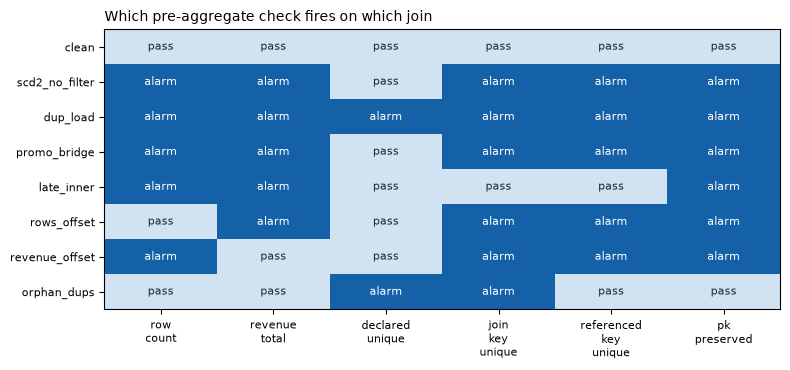

In [8]:
sc = r["scenarios"]
m = np.array([[1 if sc[k]["fires"][c] else 0 for c in CHECKS] for k in SCENARIOS])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.imshow(m, cmap="Blues", vmin=-0.3, vmax=1.3, aspect="auto")
for i in range(len(SCENARIOS)):
    for j in range(len(CHECKS)):
        ax.text(j, i, "alarm" if m[i, j] else "pass", ha="center", va="center", fontsize=8,
                color="white" if m[i, j] else "#1f2933")
ax.set_xticks(range(len(CHECKS)), [c.replace("_", "\n") for c in CHECKS], fontsize=8)
ax.set_yticks(range(len(SCENARIOS)), SCENARIOS, fontsize=8)
ax.set_title("Which pre-aggregate check fires on which join", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- A dimension with more than one row per key silently multiplies every order that matches it.
- The test a type-2 table declares, unique on (key, valid_from), passes while the join on the key fans out.
- Non-random duplicates move revenue further than rows: a row tolerance is not a revenue tolerance.
- Row count and revenue total can each be fooled by two defects that cancel.
- Assert the grain before you sum: every source key exactly once in the joined rows. It says something broke, not which join; a referenced-key uniqueness check names the dimension.

## 8. Try your own

In [9]:
# w = make_world(seed=7)                           # another fictional shop
# b = build(w, "promo_bridge")                     # or any of SCENARIOS
# print(checks(w, b))
# j = b["joined"]; print(j.order_id.is_unique, len(j), len(w["orders"]))

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version lets you pick a
broken join and see which checks pass it: `pip install -r requirements.txt && streamlit run app.py`.